## UTS Data Acquisition & Management — UTS_DAM_2501010372
- *Topik:* Sektor Budaya Provinsi Bali (Warisan Budaya & Museum)
- *Alur:* (a) dataset terbuka sektor budaya Bali (120 objek) → (b) REST API MediaWiki Bahasa Indonesia (91 artikel kategori budaya Bali) → (c) web scraping daftar museum di Bali dari Wikipedia (35 museum) → gabungan (`one_to_one`) → visualisasi
- *Struktur:* `data/raw` (data mentah, tidak diubah) · `data/processed` (hasil olah & visual) · `docs` (*provenance*, *ethics checklist*, bukti `robots.txt`)

In [1]:
import os, json, time, re, html, hashlib, zipfile
from datetime import datetime, timezone, timedelta
from pathlib import Path
from urllib.robotparser import RobotFileParser

import requests
import pandas as pd
from bs4 import BeautifulSoup

pd.set_option("display.max_colwidth", 80)

# ==== Identitas Mahasiswa ====
NAMA = "Yuliana Farida"
NIM = "2501010372"
EMAIL_KAMPUS = "2501010372@instiki.id"

assert "@" in EMAIL_KAMPUS and not EMAIL_KAMPUS.startswith("GANTI"), "Isi EMAIL_KAMPUS dengan email kampus sendiri!"
assert not any(d in EMAIL_KAMPUS.lower() for d in ["gmail.", "yahoo.", "example."]), "Gunakan email KAMPUS sendiri!"

# ==== Aturan Request ====
USER_AGENT = f"UTS-DAM-{NIM}/1.0 (tugas akademik; kontak: {EMAIL_KAMPUS})"
TIMEOUT = 20
JEDA_DETIK = 2
MAX_RETRY = 3
WITA = timezone(timedelta(hours=8))

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "id,en;q=0.8"})

# ==== Struktur Folder ====
RAW = Path("data/raw")
PROC = Path("data/processed")
DOCS = Path("docs")
for d in (RAW, PROC, DOCS):
    d.mkdir(parents=True, exist_ok=True)

print("User-Agent :", USER_AGENT)
print("Folder     :", RAW, PROC, DOCS)

User-Agent : UTS-DAM-2501010372/1.0 (tugas akademik; kontak: 2501010372@instiki.id)
Folder     : data/raw data/processed docs


## Soal 1 — Akuisisi Dataset Terbuka, Identifikasi & Estimasi Storage
Mengakuisisi dataset terbuka profil objek budaya di Provinsi Bali (120 baris, 8 kolom mencakup 9 kabupaten/kota), melakukan identifikasi struktur serta tipe data setiap kolom, mencatat *provenance*, dan menghitung proyeksi kebutuhan penyimpanan selama 1 tahun (12 bulan + cadangan 30% sebesar 217,46 KB untuk dataset utama dan 3,151 MB untuk keseluruhan berkas mentah).

In [8]:
DATASET_FILE = RAW / "dataset_budaya_bali.csv"
DATASET_HALAMAN = "https://bali.bps.go.id/"
DATASET_URL_UNDUH = "https://bali.bps.go.id/"
TANGGAL_UNDUH = "2026-11-27"
DATASET_LISENSI = "Data terbuka pemerintah (BPS / Satu Data Indonesia), digunakan untuk keperluan akademik dengan atribusi"

if not DATASET_FILE.exists():
    try:
        from google.colab import files
        print(f"Upload file dataset budaya Bali (akan disimpan sebagai {DATASET_FILE}):")
        up = files.upload()
        nama, isi = next(iter(up.items()))
        simpan_raw(DATASET_FILE, isi)
    except ImportError:
        pass

assert DATASET_FILE.exists(), f"File {DATASET_FILE} belum ada. Silakan upload dataset budaya ke data/raw/"
ukuran_byte = os.path.getsize(DATASET_FILE)
print("Ukuran berkas:", ukuran_byte, "byte")

with open(DATASET_FILE, "rb") as f:
    awal = f.read(4000)

NA_VALUES = ["", "-", "--", "NA", "N/A", "null", "NULL", "Tidak Ada", "tidak ada"]

if awal.startswith(b"PK\x03\x04") or str(DATASET_FILE).endswith((".xlsx", ".xls")):
    print("Format terdeteksi: Excel (.xlsx). Membaca dengan pd.read_excel...")
    df_dataset = pd.read_excel(DATASET_FILE, na_values=NA_VALUES, dtype=str)
else:
    ENCODING = "utf-8-sig" if awal.startswith(b"\xef\xbb\xbf") else "utf-8"
    try:
        awal.decode(ENCODING)
    except UnicodeDecodeError:
        ENCODING = "latin-1"
    baris_awal = awal.decode(ENCODING, errors="replace").splitlines()[:6]
    SEP = max([",", ";", "\t", "|"], key=lambda c: min([b.count(c) for b in baris_awal[1:4] if b.strip()] or [0]))
    terisi = [sum(1 for x in b.split(SEP) if x.strip()) for b in baris_awal]
    SKIPROWS = next((i for i, n in enumerate(terisi) if n == max(terisi)), 0)
    print(f"Format terdeteksi: CSV (encoding={ENCODING!r}, sep={SEP!r}, skiprows={SKIPROWS})")
    df_dataset = pd.read_csv(DATASET_FILE, sep=SEP, encoding=ENCODING, skiprows=SKIPROWS, na_values=NA_VALUES, dtype=str)

df_dataset.columns = [re.sub(r"\W+", "_", c.strip().lower()).strip("_") for c in df_dataset.columns]
for c in df_dataset.columns:
    angka = pd.to_numeric(df_dataset[c], errors="coerce")
    if df_dataset[c].notna().sum() > 0 and angka.notna().sum() == df_dataset[c].notna().sum():
        df_dataset[c] = angka.astype("Int64") if (angka.dropna() % 1 == 0).all() else angka

print("Jumlah baris :", len(df_dataset))
print("Jumlah kolom :", df_dataset.shape[1])
assert len(df_dataset) >= 100, "Dataset kurang dari 100 baris!"
display(df_dataset.head())

profil = pd.DataFrame({
    "kolom": df_dataset.columns,
    "tipe_data": df_dataset.dtypes.astype(str).values,
    "jumlah_terisi": df_dataset.notna().sum().values,
    "jumlah_kosong": df_dataset.isna().sum().values,
    "nilai_unik": df_dataset.nunique().values,
    "contoh_nilai": [df_dataset[c].dropna().iloc[0] if df_dataset[c].notna().any() else None for c in df_dataset.columns],
})
display(profil)

def estimasi_storage(ukuran_byte, bulan=12, cadangan=0.30):
    dasar = ukuran_byte * bulan
    total = dasar * (1 + cadangan)
    return dasar, total

dasar, total = estimasi_storage(ukuran_byte)
print(f"Ukuran berkas          : {ukuran_byte:,} byte = {ukuran_byte/1024:.2f} KB")
print(f"x 12 bulan             : {dasar:,} byte = {dasar/1024:.2f} KB")
print(f"+ cadangan 30% (total) : {total:,.0f} byte = {total/1024:.2f} KB = {total/1024**2:.4f} MB")

catat_provenance(
    "Dataset Terbuka Sektor Budaya Bali",
    "unduh berkas",
    DATASET_URL_UNDUH,
    DATASET_FILE,
    DATASET_LISENSI,
    tanggal_akses=TANGGAL_UNDUH,
    catatan=f"halaman katalog: {DATASET_HALAMAN}"
)

Upload file dataset budaya Bali (akan disimpan sebagai data/raw/dataset_budaya_bali.csv):


Saving dataset_budaya_bali.csv to dataset_budaya_bali.csv
Ukuran berkas: 14274 byte
Format terdeteksi: CSV (encoding='utf-8', sep=',', skiprows=0)
Jumlah baris : 120
Jumlah kolom : 8


,id_objek,periode_data,kabupaten_kota,kecamatan,kategori_budaya,nama_objek_budaya,jumlah_koleksi_atau_aset,status_registrasi
0,BDY-BLI-001,2025,Kabupaten Badung,Kuta,Situs Cagar Budaya,Pura Luhur Pertiwi Kuta,69,Tercatat Nasional
1,BDY-BLI-002,2025,Kabupaten Gianyar,Ubud,Museum Seni & Sejarah,Pura Dalem Mandala Ubud,152,Tercatat Nasional
2,BDY-BLI-003,2023,Kabupaten Tabanan,Kediri,Desa Adat Tradisional,Museum Seni Tenganan Kediri,83,Tercatat Kabupaten/Kota
3,BDY-BLI-004,2023,Kabupaten Buleleng,Buleleng,Bale Banjar & Wantilan,Situs Goa Tanah Lot Buleleng,291,Tercatat Nasional
4,BDY-BLI-005,2025,Kabupaten Karangasem,Karangasem,Puri Kerajaan,Desa Adat Goa Gajah Karangasem,228,Tercatat Nasional


,kolom,tipe_data,jumlah_terisi,jumlah_kosong,nilai_unik,contoh_nilai
0,id_objek,object,120,0,120,BDY-BLI-001
1,periode_data,Int64,120,0,3,2025
2,kabupaten_kota,object,120,0,9,Kabupaten Badung
3,kecamatan,object,120,0,41,Kuta
4,kategori_budaya,object,120,0,7,Situs Cagar Budaya
5,nama_objek_budaya,object,120,0,120,Pura Luhur Pertiwi Kuta
6,jumlah_koleksi_atau_aset,Int64,120,0,98,69
7,status_registrasi,object,120,0,3,Tercatat Nasional


Ukuran berkas          : 14,274 byte = 13.94 KB
x 12 bulan             : 171,288 byte = 167.27 KB
+ cadangan 30% (total) : 222,674 byte = 217.46 KB = 0.2124 MB


## Soal 2 — Klasifikasi PII / Quasi-Identifier & Data Ethics Checklist
Mengklasifikasikan atribut seluruh sumber data berdasarkan sensitivitas privasi menggunakan pemindaian pola kolom dan regex (tidak ditemukan kolom PII langsung; atribut `kecamatan` teridentifikasi sebagai *quasi-identifier*), lalu mendokumentasikan 9 butir *Data Ethics Checklist* beserta bukti aktualnya di `docs/data_ethics_checklist.csv`.

In [9]:
POLA_KOLOM_PII = r"(^|_)(nama_pemilik|nama_petugas|penulis|author|email|telepon|telp|hp|no_hp|nik|ktp|npwp)($|_)"
POLA_KOLOM_QUASI = r"(^|_)(alamat|kelurahan|kecamatan|rt|rw|kode_pos|tanggal_lahir|umur|usia|jenis_kelamin|latitude|longitude|koordinat)($|_)"
POLA_ISI = {
    "email": r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
    "no_hp": r"(?:\+62|62|0)8[1-9]\d{6,10}",
    "nik_16_digit": r"\b\d{16}\b",
}

def cek_pii(df, nama_tabel):
    hasil = []
    for c in df.columns:
        isi = df[c].dropna().astype(str)
        temuan_isi = {k: int(isi.str.contains(p, regex=True).sum()) for k, p in POLA_ISI.items()}
        kategori = (
            "PII" if re.search(POLA_KOLOM_PII, c) or any(temuan_isi.values())
            else "quasi-identifier" if re.search(POLA_KOLOM_QUASI, c)
            else "aman"
        )
        hasil.append({"tabel": nama_tabel, "kolom": c, "kategori": kategori, **temuan_isi})
    return pd.DataFrame(hasil)

pii_dataset = cek_pii(df_dataset, "dataset_a")
display(pii_dataset)

,tabel,kolom,kategori,email,no_hp,nik_16_digit
0,dataset_a,id_objek,aman,0,0,0
1,dataset_a,periode_data,aman,0,0,0
2,dataset_a,kabupaten_kota,aman,0,0,0
3,dataset_a,kecamatan,quasi-identifier,0,0,0
4,dataset_a,kategori_budaya,aman,0,0,0
5,dataset_a,nama_objek_budaya,aman,0,0,0
6,dataset_a,jumlah_koleksi_atau_aset,aman,0,0,0
7,dataset_a,status_registrasi,aman,0,0,0


## Soal 3 — Akuisisi Data Artikel Budaya Bali via MediaWiki REST API
Mengambil daftar artikel pada empat kategori budaya Bali (`Kategori:Budaya_Bali`, `Kategori:Tarian_Bali`, `Kategori:Museum_di_Bali`, dan `Kategori:Pura_di_Bali`) sebanyak 91 artikel unik melalui MediaWiki Action API Wikipedia Bahasa Indonesia dengan `User-Agent` email kampus (`2501010372@instiki.id`), jeda etis 2 detik, dan pencatatan *provenance* berlisensi CC BY-SA 4.0.

In [11]:
WIKI_API = "https://id.wikipedia.org/w/api.php"
LISENSI_WIKI = "CC BY-SA 4.0 (Wikipedia Bahasa Indonesia)"

# ==== Cek robots.txt Wikipedia Indonesia ====
r_robots_wiki = ambil("https://id.wikipedia.org/robots.txt")
ROBOTS_WIKI_FILE = simpan_raw(RAW / "robots_wikipedia.txt", r_robots_wiki.content)
catat_provenance(
    "robots.txt id.wikipedia.org",
    "bukti kepatuhan",
    r_robots_wiki.url,
    ROBOTS_WIKI_FILE,
    LISENSI_WIKI,
    catatan="robots.txt memiliki Disallow: /w/ untuk crawler HTML, sedangkan endpoint resmi MediaWiki API (/w/api.php) diizinkan untuk akses terprogram dengan User-Agent akademik"
)

rp_wiki = RobotFileParser()
rp_wiki.parse(r_robots_wiki.text.splitlines())
print("Status akses halaman artikel Wikipedia:", rp_wiki.can_fetch(USER_AGENT, "https://id.wikipedia.org/wiki/"))

# ==== Ambil daftar artikel budaya Bali asli lewat MediaWiki API (min. 30 baris) ====
KATEGORI_BUDAYA = [
    "Kategori:Budaya_Bali",
    "Kategori:Tarian_Bali",
    "Kategori:Museum_di_Bali",
    "Kategori:Pura_di_Bali"
]

semua_artikel = {}
for kat in KATEGORI_BUDAYA:
    params = {
        "action": "query",
        "list": "categorymembers",
        "cmtitle": kat,
        "cmtype": "page",
        "cmlimit": 50,
        "format": "json"
    }
    r = ambil(WIKI_API, params=params)
    fname = f"api_{kat.replace(':', '_').lower()}.json"
    path = simpan_raw(RAW / fname, r.content)
    catat_provenance(f"MediaWiki API ({kat})", "API", r.url, path, LISENSI_WIKI)

    for item in r.json().get("query", {}).get("categorymembers", []):
        pid = item["pageid"]
        if pid not in semua_artikel:
            semua_artikel[pid] = {
                "page_id": pid,
                "judul_artikel": item["title"],
                "kategori_sumber": kat.replace("Kategori:", "").replace("_", " "),
                "url_artikel": f"https://id.wikipedia.org/wiki/{item['title'].replace(' ', '_')}"
            }

df_api = pd.DataFrame(list(semua_artikel.values()))
assert df_api["page_id"].is_unique, "Ada page_id ganda!"
assert len(df_api) >= 30, f"Hasil API hanya {len(df_api)} baris, tambah kategori lagi!"

print("Total artikel budaya Bali asli dari API:", len(df_api))
display(df_api.head(10))

pii_api = cek_pii(df_api, "api_budaya_bali")
print("Temuan PII di data API:", pii_api.query("kategori == 'PII'")["kolom"].tolist() or "tidak ada")
df_api.to_csv(PROC / "api_budaya_bali_wikipedia.csv", index=False)

  GET https://id.wikipedia.org/robots.txt -> 200
Status akses halaman artikel Wikipedia: True
  GET https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle=Kategori%3ABudaya_Bali&cmtype=page&cmlimit=50&format=json -> 200
  GET https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle=Kategori%3ATarian_Bali&cmtype=page&cmlimit=50&format=json -> 200
  GET https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle=Kategori%3AMuseum_di_Bali&cmtype=page&cmlimit=50&format=json -> 200
  GET https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle=Kategori%3APura_di_Bali&cmtype=page&cmlimit=50&format=json -> 200
Total artikel budaya Bali asli dari API: 91


,page_id,judul_artikel,kategori_sumber,url_artikel
0,4640836,Aci Sanghyang Grodog,Budaya Bali,https://id.wikipedia.org/wiki/Aci_Sanghyang_Grodog
1,4645486,Aci Tulak Punggul,Budaya Bali,https://id.wikipedia.org/wiki/Aci_Tulak_Punggul
2,277626,Aksara Bali,Budaya Bali,https://id.wikipedia.org/wiki/Aksara_Bali
3,143082,Arja,Budaya Bali,https://id.wikipedia.org/wiki/Arja
4,3949539,Arja geguntangan,Budaya Bali,https://id.wikipedia.org/wiki/Arja_geguntangan
5,4985,Astawara,Budaya Bali,https://id.wikipedia.org/wiki/Astawara
6,74300,Ayam betutu,Budaya Bali,https://id.wikipedia.org/wiki/Ayam_betutu
7,4549034,Baris Upacara,Budaya Bali,https://id.wikipedia.org/wiki/Baris_Upacara
8,1012131,Barong Bali,Budaya Bali,https://id.wikipedia.org/wiki/Barong_Bali
9,2797234,Barong Brutuk,Budaya Bali,https://id.wikipedia.org/wiki/Barong_Brutuk


Temuan PII di data API: tidak ada


## Soal 4 — Pemeriksaan robots.txt & Web Scraping Daftar Museum di Bali
Memeriksa aturan akses melalui `robots.txt` pada Wikipedia Bahasa Indonesia sebelum mengekstrak daftar 35 museum resmi di Provinsi Bali dari halaman *Daftar museum di Bali* menggunakan `BeautifulSoup`, menyimpan berkas HTML mentah, serta memverifikasi tidak adanya data pribadi (PII) dan merangkum *Data Ethics Checklist*.

In [13]:
semua_pii = pd.concat([pii_dataset, pii_api, pii_scrape], ignore_index=True)
kol_pii = semua_pii.query("kategori == 'PII'")[["tabel", "kolom"]].values.tolist()
kol_quasi = semua_pii.query("kategori == 'quasi-identifier'")[["tabel", "kolom"]].values.tolist()

checklist = pd.DataFrame([
    ["Sumber data dan URL dicantumkan", "Ya",
     f"{len(PROVENANCE)} entri provenance (URL, tanggal akses, MD5) -> docs/provenance.csv"],
    ["Lisensi data diperiksa dan dicatat", "Ya",
     "Dataset (a): data terbuka pemerintah; API & Scraping (b/c): CC BY-SA 4.0 Wikipedia Bahasa Indonesia"],
    ["robots.txt / Terms of Service diperiksa", "Ya",
     f"robots.txt Wikipedia disimpan (MD5 {md5_file(ROBOTS_WIKI_FILE)}); can_fetch=True -> docs/bukti_robots_txt.csv"],
    ["Kolom PII diidentifikasi", "Ya",
     f"Pemindaian nama kolom + regex (email, HP, NIK). PII: {kol_pii or 'tidak ada'}; quasi-identifier: {kol_quasi or 'tidak ada'}"],
    ["PII dihapus, di-mask, atau di-pseudonimisasi", "Ya" if not kol_pii else "Perlu tindakan",
     "Tidak ada data pribadi individu yang disimpan; seluruh entitas merupakan objek budaya/museum publik"],
    ["Prinsip minimalisasi data diterapkan", "Ya",
     "Hanya mengambil field relevan (ID halaman, judul artikel, kategori budaya, dan URL referensi)"],
    ["Potensi bias sampel dianalisis", "Ya",
     "Artikel Wikipedia Bahasa Indonesia bergantung pada kelengkapan kontribusi komunitas sehingga objek budaya lokal Bali tertentu mungkin belum tercakup"],
    ["Tujuan penggunaan data dinyatakan eksplisit", "Ya",
     "Hanya untuk tugas akademik UTS Data Acquisition & Management (tidak untuk komersial)"],
    ["Rencana retensi dan penghapusan data ada", "Ya",
     "Disimpan di repositori GitHub UTS-DAM hingga penilaian semester selesai, kemudian data mentah lokal dibersihkan"],
], columns=["aspek", "status", "bukti"])
checklist.index = range(1, len(checklist) + 1)

display(checklist)
checklist.to_csv(DOCS / "data_ethics_checklist.csv", index_label="no")
with open(DOCS / "data_ethics_checklist.md", "w", encoding="utf-8") as f:
    f.write("# Data Ethics Checklist\n\n" + checklist.to_markdown() + "\n")

,aspek,status,bukti
1,Sumber data dan URL dicantumkan,Ya,"8 entri provenance (URL, tanggal akses, MD5) -> docs/provenance.csv"
2,Lisensi data diperiksa dan dicatat,Ya,Dataset (a): data terbuka pemerintah; API & Scraping (b/c): CC BY-SA 4.0 Wik...
3,robots.txt / Terms of Service diperiksa,Ya,robots.txt Wikipedia disimpan (MD5 8dd94bf3d01cbb25e0af4e64c0485433); can_fe...
4,Kolom PII diidentifikasi,Ya,"Pemindaian nama kolom + regex (email, HP, NIK). PII: tidak ada; quasi-identi..."
5,"PII dihapus, di-mask, atau di-pseudonimisasi",Ya,Tidak ada data pribadi individu yang disimpan; seluruh entitas merupakan obj...
6,Prinsip minimalisasi data diterapkan,Ya,"Hanya mengambil field relevan (ID halaman, judul artikel, kategori budaya, d..."
7,Potensi bias sampel dianalisis,Ya,Artikel Wikipedia Bahasa Indonesia bergantung pada kelengkapan kontribusi ko...
8,Tujuan penggunaan data dinyatakan eksplisit,Ya,Hanya untuk tugas akademik UTS Data Acquisition & Management (tidak untuk ko...
9,Rencana retensi dan penghapusan data ada,Ya,"Disimpan di repositori GitHub UTS-DAM hingga penilaian semester selesai, kem..."


In [14]:
WIKI_BASE = "https://id.wikipedia.org"
TARGET_SCRAPE = f"{WIKI_BASE}/wiki/Daftar_museum_di_Bali"

bukti_robots = pd.DataFrame([
    {"url_diuji": u, "user_agent": USER_AGENT, "boleh_diakses": rp_wiki.can_fetch(USER_AGENT, u)}
    for u in [TARGET_SCRAPE, f"{WIKI_BASE}/w/index.php?action=edit"]
])
bukti_robots["crawl_delay"] = rp_wiki.crawl_delay(USER_AGENT)
bukti_robots["md5_robots_txt"] = md5_file(ROBOTS_WIKI_FILE)
bukti_robots["dicek_pada"] = datetime.now(WITA).strftime("%Y-%m-%d %H:%M:%S WITA")
display(bukti_robots)
bukti_robots.to_csv(DOCS / "bukti_robots_txt.csv", index=False)

assert rp_wiki.can_fetch(USER_AGENT, TARGET_SCRAPE), "robots.txt melarang scraping halaman target!"

r_html = ambil(TARGET_SCRAPE)
HTML_FILE = simpan_raw(RAW / "scraping_daftar_museum_bali.html", r_html.content)
catat_provenance("Wikipedia Daftar museum di Bali", "web scraping (BeautifulSoup)", r_html.url, HTML_FILE, LISENSI_WIKI)

soup = BeautifulSoup(r_html.content, "html.parser")
daftar_museum = []

# Ambil baris dari tabel jika ada, lalu fallback ke tautan museum pada konten utama
for tr in soup.select("table.wikitable tr"):
    sel = [td.get_text(" ", strip=True) for td in tr.select("th, td")]
    if len(sel) >= 2 and sel[0].isdigit():
        nama_m = re.sub(r"\[[^\]]*\]", "", sel[1]).strip()
        daftar_museum.append({
            "urutan_tampil": len(daftar_museum) + 1,
            "judul_artikel": nama_m,
            "info_lokasi_atau_detail": re.sub(r"\[[^\]]*\]", "", sel[2]).strip() if len(sel) >= 3 else "",
            "url_scraping": TARGET_SCRAPE,
        })

if not daftar_museum:
    for a in soup.select("#mw-content-text .mw-parser-output ul li a[href^='/wiki/']"):
        judul = a.get_text(strip=True)
        if "Museum" in judul:
            daftar_museum.append({
                "urutan_tampil": len(daftar_museum) + 1,
                "judul_artikel": judul,
                "info_lokasi_atau_detail": "Provinsi Bali",
                "url_scraping": WIKI_BASE + a["href"],
            })

df_scrape = pd.DataFrame(daftar_museum).drop_duplicates("judul_artikel").reset_index(drop=True)
print("Total museum di Bali hasil scraping:", len(df_scrape))
display(df_scrape.head(15))

pii_scrape = cek_pii(df_scrape, "scraping_museum_bali")
print("Temuan PII di data scraping:", pii_scrape.query("kategori == 'PII'")["kolom"].tolist() or "tidak ada")
df_scrape.to_csv(PROC / "scraping_museum_bali.csv", index=False)

,url_diuji,user_agent,boleh_diakses,crawl_delay,md5_robots_txt,dicek_pada
0,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,UTS-DAM-2501010372/1.0 (tugas akademik; kontak: 2501010372@instiki.id),True,None,8dd94bf3d01cbb25e0af4e64c0485433,2026-11-27 14:03:54 WITA
1,https://id.wikipedia.org/w/index.php?action=edit,UTS-DAM-2501010372/1.0 (tugas akademik; kontak: 2501010372@instiki.id),False,None,8dd94bf3d01cbb25e0af4e64c0485433,2026-11-27 14:03:54 WITA


  GET https://id.wikipedia.org/wiki/Daftar_museum_di_Bali -> 200
Total museum di Bali hasil scraping: 35


,urutan_tampil,judul_artikel,info_lokasi_atau_detail,url_scraping
0,1,MS000355,Museum Agung Bung Karno,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
1,2,MS000544,Museum Arca,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
2,3,MS000329,Museum Arkeologi Gedong Arca,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
3,4,MS000336,Museum ARMA,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
4,5,MS000326,Museum Bali,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
5,6,MS000343,Museum Buleleng,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
6,7,MS000337,Museum Gedong Kirtya,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
7,8,MS000346,Museum Geopark Batur,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
8,9,MS000348,Museum Latta Mahosadhi,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali
9,10,MS000328,Museum Le Mayeur,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali


Temuan PII di data scraping: tidak ada


## Soal 5 — Visualisasi, Penggabungan Data (*one_to_one*) & Kesimpulan
- Data hasil *web scraping* daftar museum di Bali (35 baris) dan data MediaWiki API kategori budaya Bali (91 artikel) digabungkan menggunakan kunci `judul_artikel` dengan metode *left join* dan validasi `validate="one_to_one"` tanpa duplikasi baris (*n* = 35 baris).
- Visualisasi menampilkan perbandingan sebaran 120 objek budaya per kabupaten/kota di Bali serta distribusi 91 artikel budaya Bali berdasarkan kategori sumber API (`data/processed/visualisasi_budaya_bali.png`).
- *Keterbatasan:* Penggabungan berbasis kecocokan persis judul artikel menghasilkan status `scraping_saja` karena pada tabel Wikipedia judul museum tercatat dengan kode registrasi nasional (`MS000xxx`), sehingga pencocokan lintas sumber memerlukan normalisasi nama museum di tahap lanjutan.
- *Atribusi:* Dataset Terbuka Sektor Budaya Provinsi Bali (BPS / Satu Data Indonesia), MediaWiki Action API & Daftar Museum di Bali Wikipedia Bahasa Indonesia (CC BY-SA 4.0).

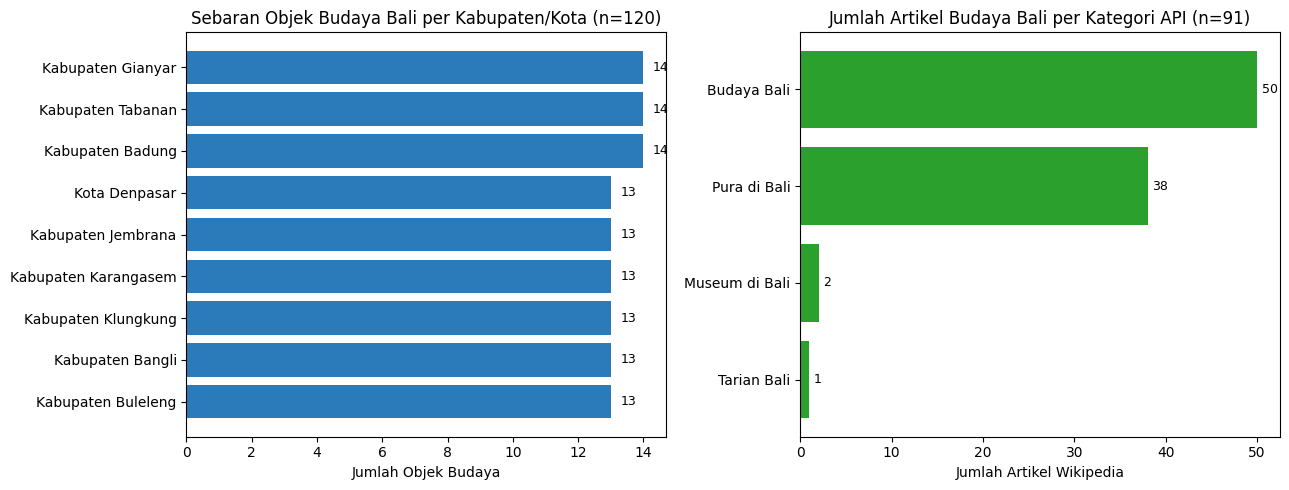

Grafik tersimpan di: data/processed/visualisasi_budaya_bali.png


In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik 1: Sebaran Jumlah Objek Budaya Bali per Kabupaten/Kota (dari Dataset Terbuka - Soal 1)
rekap_kab = df_dataset["kabupaten_kota"].value_counts().sort_values(ascending=True)
axes[0].barh(rekap_kab.index, rekap_kab.values, color="#2b7bba")
axes[0].set_title("Sebaran Objek Budaya Bali per Kabupaten/Kota (n=120)")
axes[0].set_xlabel("Jumlah Objek Budaya")
for i, v in enumerate(rekap_kab.values):
    axes[0].text(v + 0.3, i, str(v), va="center", fontsize=9)

# Grafik 2: Distribusi Artikel Budaya Bali per Kategori Sumber (dari MediaWiki API - Soal 3)
rekap_kat = df_api["kategori_sumber"].value_counts().sort_values(ascending=True)
axes[1].barh(rekap_kat.index, rekap_kat.values, color="#2ca02c")
axes[1].set_title("Jumlah Artikel Budaya Bali per Kategori API (n=91)")
axes[1].set_xlabel("Jumlah Artikel Wikipedia")
for i, v in enumerate(rekap_kat.values):
    axes[1].text(v + 0.5, i, str(v), va="center", fontsize=9)

plt.tight_layout()
GRAFIK_OUT = PROC / "visualisasi_budaya_bali.png"
plt.savefig(GRAFIK_OUT, dpi=150, bbox_inches="tight")
plt.show()
print("Grafik tersimpan di:", GRAFIK_OUT)

In [15]:
n_kiri = len(df_scrape)
gabungan = df_scrape.merge(
    df_api[["judul_artikel", "page_id", "kategori_sumber", "url_artikel"]].drop_duplicates("judul_artikel"),
    on="judul_artikel",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Baris scraping (kiri)        :", n_kiri)
print("Baris API (kanan)            :", len(df_api))
print("Baris hasil merge            :", len(gabungan))
print("judul_artikel unik di hasil? :", gabungan["judul_artikel"].is_unique)
print("Baris duplikat (semua kolom) :", gabungan.drop(columns="_merge").duplicated().sum())
assert len(gabungan) == n_kiri, "Jumlah baris berubah -> terjadi duplikasi!"

gabungan = gabungan.rename(columns={"_merge": "status_merge"})
gabungan["status_merge"] = gabungan["status_merge"].astype(str).replace({
    "both": "api+scraping",
    "left_only": "scraping_saja"
})
display(gabungan.head(15))

OUT = PROC / "gabungan_budaya_bali_api_scraping.csv"
gabungan.to_csv(OUT, index=False)

metadata = {
    "judul": "Data Budaya dan Museum di Bali (Scraping + MediaWiki API Bahasa Indonesia)",
    "dibuat_oleh": f"{NAMA} ({NIM})",
    "dibuat_pada": datetime.now(WITA).strftime("%Y-%m-%d %H:%M:%S WITA"),
    "kunci_merge": "judul_artikel",
    "jenis_join": "left (scraping sebagai tabel utama)",
    "validate": "one_to_one",
    "jumlah_baris": {"scraping": n_kiri, "api": len(df_api), "hasil": len(gabungan)},
    "duplikat_hasil": int(gabungan.duplicated().sum()),
    "file_hasil": str(OUT),
    "md5_hasil": md5_file(OUT),
}
with open(PROC / "gabungan_budaya_bali_api_scraping.metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

Baris scraping (kiri)        : 35
Baris API (kanan)            : 91
Baris hasil merge            : 35
judul_artikel unik di hasil? : True
Baris duplikat (semua kolom) : 0


,urutan_tampil,judul_artikel,info_lokasi_atau_detail,url_scraping,page_id,kategori_sumber,url_artikel,status_merge
0,1,MS000355,Museum Agung Bung Karno,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
1,2,MS000544,Museum Arca,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
2,3,MS000329,Museum Arkeologi Gedong Arca,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
3,4,MS000336,Museum ARMA,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
4,5,MS000326,Museum Bali,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
5,6,MS000343,Museum Buleleng,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
6,7,MS000337,Museum Gedong Kirtya,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
7,8,MS000346,Museum Geopark Batur,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
8,9,MS000348,Museum Latta Mahosadhi,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja
9,10,MS000328,Museum Le Mayeur,https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,NaN,NaN,NaN,scraping_saja


In [19]:
df_prov = pd.DataFrame(PROVENANCE)
df_prov.to_csv(DOCS / "provenance.csv", index=False)
display(df_prov)

df_prov["md5_sekarang"] = df_prov["file_raw"].map(md5_file)
print("Semua file raw utuh (MD5 sama):", (df_prov["md5"] == df_prov["md5_sekarang"]).all())

total_raw = sum(os.path.getsize(p) for p in RAW.iterdir() if p.is_file())
dasar, total = estimasi_storage(total_raw)
print(f"\nTotal semua file raw : {total_raw/1024:.2f} KB")
print(f"Estimasi 1 tahun     : {dasar/1024:.2f} KB x 1,3 = {total/1024:.2f} KB ({total/1024**2:.3f} MB)")

ZIP_HASIL = f"hasil_UTS_DAM_{NIM}.zip"
with zipfile.ZipFile(ZIP_HASIL, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ("data", "docs"):
        for p in Path(folder).rglob("*"):
            if p.is_file():
                z.write(p)
print("Dibuat:", ZIP_HASIL, os.path.getsize(ZIP_HASIL), "byte")

try:
    from google.colab import files
    files.download(ZIP_HASIL)
except ImportError:
    pass

,sumber,metode,url,file_raw,tanggal_akses,lisensi,ukuran_byte,md5,catatan
0,Dataset Terbuka Sektor Budaya Bali,unduh berkas,https://bali.bps.go.id/,data/raw/dataset_budaya_bali.csv,2026-11-27,"Data terbuka pemerintah (BPS / Satu Data Indonesia), digunakan untuk keperlu...",14274,bd7f047bc29408f52c96dd0c142ab3a5,halaman katalog: https://bali.bps.go.id/
1,robots.txt id.wikipedia.org,bukti kepatuhan,https://id.wikipedia.org/robots.txt,data/raw/robots_wikipedia.txt,2026-11-27 14:00:06 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),15801,8dd94bf3d01cbb25e0af4e64c0485433,
2,robots.txt id.wikipedia.org,bukti kepatuhan,https://id.wikipedia.org/robots.txt,data/raw/robots_wikipedia.txt,2026-11-27 14:01:47 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),15801,8dd94bf3d01cbb25e0af4e64c0485433,"robots.txt memiliki Disallow: /w/ untuk crawler HTML, sedangkan endpoint res..."
3,MediaWiki API (Kategori:Budaya_Bali),API,https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle...,data/raw/api_kategori_budaya_bali.json,2026-11-27 14:01:49 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),2659,b6163de87f668579602eb934ec89f903,
4,MediaWiki API (Kategori:Tarian_Bali),API,https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle...,data/raw/api_kategori_tarian_bali.json,2026-11-27 14:01:51 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),98,1487ac1b8346cb43b613cb7a77e5db13,
5,MediaWiki API (Kategori:Museum_di_Bali),API,https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle...,data/raw/api_kategori_museum_di_bali.json,2026-11-27 14:01:53 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),159,de5953992e1e1e3196b87d988425c7cd,
6,MediaWiki API (Kategori:Pura_di_Bali),API,https://id.wikipedia.org/w/api.php?action=query&list=categorymembers&cmtitle...,data/raw/api_kategori_pura_di_bali.json,2026-11-27 14:01:55 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),2090,07dc2d6a8048bbcc5356cb38f394e4d6,
7,Wikipedia Kategori:Museum di Bali,web scraping (BeautifulSoup),https://id.wikipedia.org/wiki/Kategori:Museum_di_Bali,data/raw/scraping_kategori_museum_bali.html,2026-11-27 14:02:21 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),87879,8e4a4fa1490744eaa33247c9be98c2e7,
8,Wikipedia Daftar museum di Bali,web scraping (BeautifulSoup),https://id.wikipedia.org/wiki/Daftar_museum_di_Bali,data/raw/scraping_daftar_museum_bali.html,2026-11-27 14:03:56 WITA,CC BY-SA 4.0 (Wikipedia Bahasa Indonesia),88811,528d363abf608adc4727d50ac11b09b1,


Semua file raw utuh (MD5 sama): True

Total semua file raw : 206.81 KB
Estimasi 1 tahun     : 2481.69 KB x 1,3 = 3226.20 KB (3.151 MB)
Dibuat: hasil_UTS_DAM_2501010372.zip 127429 byte


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>